In [2]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 202608
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.2,
})
n = 2000

$
  \text{A: }X,Y\overset{\mathrm{iid}}\sim\mathcal N(0,1),
  \qquad
  \text{B: }X\sim\operatorname{Unif}(-1,1),\
    Y=X^2+0.05\varepsilon,\quad
    \varepsilon\sim\mathcal N(0,1),
$

In [22]:
xa = rng.normal(0, 1, size=(n,))
ya = rng.normal(0, 1, size=(n,))
cov_a = np.cov(xa, ya, ddof=1)[0, 1]
corr_a = cov_a/(np.std(xa)*np.std(ya))

xb = rng.uniform(-1, 1, size=(n,))
yb = xb + rng.normal(0, 1, size=(n,))
cov_b = np.cov(xb, yb, ddof=1)[0, 1]
corr_b = cov_b/(np.std(xb)*np.std(yb))


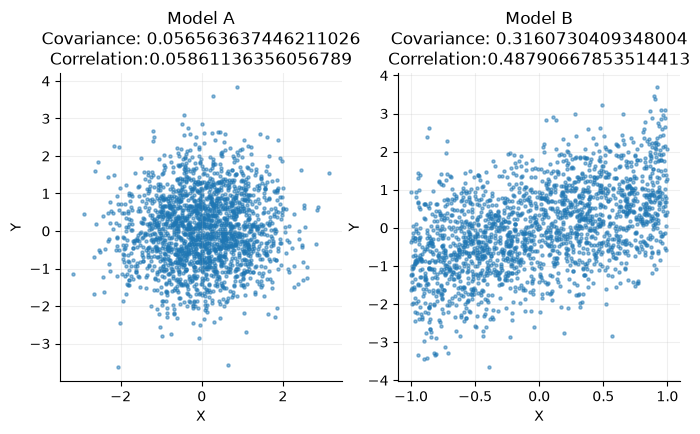

In [28]:
fig, ax = plt.subplots(1,2, figsize=(8,4))

ax[0].scatter(xa,ya, s=5, alpha=0.5)
ax[0].set(xlabel='X', ylabel='Y', title=f"Model A\nCovariance: {cov_a}\nCorrelation:{corr_a}")
ax[1].scatter(xb,yb, s=5, alpha=0.5)
ax[1].set(xlabel='X', ylabel='Y', title=f"Model B\nCovariance: {cov_b}\nCorrelation:{corr_b}")

plt.show()

Independent bin counts: [200 200 200 200 200 200 200 200 200 200]
Dependent   bin counts: [200 200 200 200 200 200 200 200 200 200]


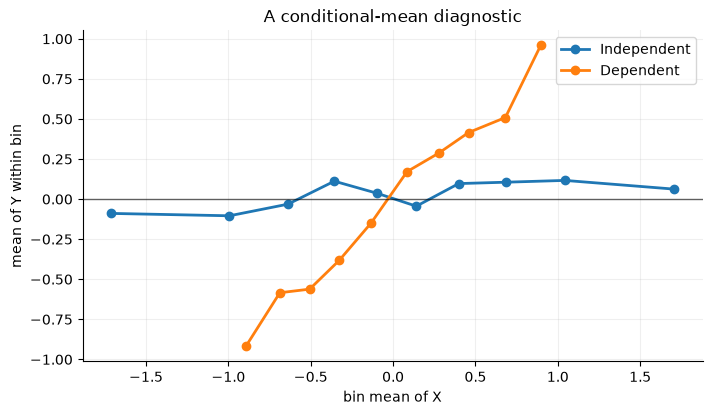

In [29]:
def binned_means(x, y, n_bins=10):
    edges = np.quantile(x, np.linspace(0.0, 1.0, n_bins + 1))
    groups = np.clip(np.digitize(x, edges[1:-1]), 0, n_bins - 1)
    centers = np.array([x[groups == k].mean() for k in range(n_bins)])
    means = np.array([y[groups == k].mean() for k in range(n_bins)])
    counts = np.array([(groups == k).sum() for k in range(n_bins)])
    return centers, means, counts

fig, ax = plt.subplots(figsize=(8, 4.3))
for name, x, y in [
    ("Independent", xa, ya),
    ("Dependent", xb, yb),
]:
    centers, means, counts = binned_means(x, y)
    ax.plot(centers, means, marker="o", linewidth=2, label=name)
    print(f"{name:11s} bin counts: {counts}")
ax.axhline(0.0, color="black", linewidth=1, alpha=0.6)
ax.set(xlabel="bin mean of X", ylabel="mean of Y within bin",
       title="A conditional-mean diagnostic")
ax.legend()
plt.show()